# Import Library dan Load Data

In [1]:
# Import semua library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load semua tabel yang dibutuhkan
pd.set_option('display.max_columns', None)
path = 'D:/olist-project/data/raw/'

customers = pd.read_csv(path + 'olist_customers_dataset.csv')
orders = pd.read_csv(path + 'olist_orders_dataset.csv')
items = pd.read_csv(path + 'olist_order_items_dataset.csv')
payments = pd.read_csv(path + 'olist_order_payments_dataset.csv')
reviews = pd.read_csv(path + 'olist_order_reviews_dataset.csv')
products = pd.read_csv(path + 'olist_products_dataset.csv')
sellers = pd.read_csv(path + 'olist_sellers_dataset.csv')
categories = pd.read_csv(path + 'product_category_name_translation.csv')


In [3]:
# Lihat ukuran dan isi setiap tabel
tables = {
    'customers': customers,
    'orders': orders,
    'items': items,
    'payments': payments,
    'reviews': reviews,
    'products': products,
    'sellers': sellers,
    'categories': categories
}

# Tampilkan jumlah baris dan kolom dari setiap tabel
for name, df in tables.items():
    print(f"{name:10s} -> {df.shape[0]:>7,} baris, {df.shape[1]:>2} kolom")

customers  ->  99,441 baris,  5 kolom
orders     ->  99,441 baris,  8 kolom
items      -> 112,650 baris,  7 kolom
payments   -> 103,886 baris,  5 kolom
reviews    ->  99,224 baris,  7 kolom
products   ->  32,951 baris,  9 kolom
sellers    ->   3,095 baris,  4 kolom
categories ->      71 baris,  2 kolom


# Cek Kualitas Data

## a. Missing Value

In [4]:
# cek kualitas data dari setiap tabel
## Missing Values
for name, df in tables.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print(f"\n==={name}===\n")
    print(miss if len(miss) else "Tidak ada missing value")


===customers===

Tidak ada missing value

===orders===

order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

===items===

Tidak ada missing value

===payments===

Tidak ada missing value

===reviews===

review_comment_title      87656
review_comment_message    58247
dtype: int64

===products===

product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

===sellers===

Tidak ada missing value

===categories===

Tidak ada missing value


## B. Melihat duplikat dan keunikan kunci

In [5]:
## Duplikat 
for name, df in tables.items():
    print(f"Jumlah duplikat di {name:10s}: {df.duplicated().sum()}")

## Keunikan kunci
print("\nKeunikan kunci:")
print("orders.order_id unik        :", orders["order_id"].is_unique)
print("customers.customer_id unik  :", customers["customer_id"].is_unique)
print("customer_unique_id unik     :", customers["customer_unique_id"].nunique(),
      "dari", len(customers), "baris")
print("order_id unik di reviews    :", reviews["order_id"].nunique(),
      "dari", len(reviews), "baris")
print("order_id unik di payments   :", payments["order_id"].nunique(),
      "dari", len(payments), "baris")

Jumlah duplikat di customers : 0
Jumlah duplikat di orders    : 0
Jumlah duplikat di items     : 0
Jumlah duplikat di payments  : 0
Jumlah duplikat di reviews   : 0
Jumlah duplikat di products  : 0
Jumlah duplikat di sellers   : 0
Jumlah duplikat di categories: 0

Keunikan kunci:
orders.order_id unik        : True
customers.customer_id unik  : True
customer_unique_id unik     : 96096 dari 99441 baris
order_id unik di reviews    : 98673 dari 99224 baris
order_id unik di payments   : 99440 dari 103886 baris


## C. Tipe data dan kolom tanggak di orders

In [6]:
# Tipe data dan kolom tanggal di orders
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [7]:
# ubah kolom tanggal menjadi tipe datetime
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

print(orders["order_purchase_timestamp"].min(), "sampai",
        orders["order_purchase_timestamp"].max())

2016-09-04 21:15:19 sampai 2018-10-17 17:30:18


## D. Distribusi status order

In [8]:
# Distribusi status order
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

## E. Konversi tanggal di items dan reviews

In [9]:
# konversi tanggal items dan reviews
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

# Merge Tabel dan buat kolom turunan

## a. Bersihkan products dan tambahkan nama kategori inggris

In [10]:
# Bersihkan products dan tambahkan nama kategori Inggris
products["product_category_name"] = products["product_category_name"].fillna("unknown")

products = products.merge(categories, on="product_category_name", how="left")

products["category_en"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"])
)

## b. Ambil satu review per order

In [11]:
# Ambil satu review per order
reviews_clean = (
    reviews.sort_values("review_answer_timestamp")
           .drop_duplicates(subset="order_id", keep="last")
           [["order_id", "review_score"]]
)

## C. Agregasi pembayaran per order (dipakai untuk analisis tingkat order, tidak untuk merge ke tabel item)


In [12]:
# Agregasi pembayaran per order (dipakai untuk analisis tingkat order, tidak untuk merge ke tabel item)
payments_agg = (
    payments.groupby("order_id")
            .agg(payment_value=("payment_value", "sum"),
                 n_payment_methods=("payment_type", "nunique"))
            .reset_index()
)

## D. Filter order yang sudah terkirim


In [13]:
# Filter order yang sudah terkirim
orders_del = orders[orders["order_status"] == "delivered"].copy()
orders_del = orders_del.dropna(subset=["order_delivered_customer_date"])

## E. Gabungkan semua tabel (level item)


In [14]:
# Gabungkan semua tabel (level item)
df = (
    orders_del
    .merge(customers, on="customer_id", how="left")
    .merge(items, on="order_id", how="left")
    .merge(products[["product_id", "category_en"]], on="product_id", how="left")
    .merge(sellers, on="seller_id", how="left")
    .merge(reviews_clean, on="order_id", how="left")
)

## F. Buat kolom turunan


In [15]:
# Buat kolom turunan
df["order_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["item_total"] = df["price"] + df["freight_value"]

df["delivery_days"] = (df["order_delivered_customer_date"]
                       - df["order_purchase_timestamp"]).dt.days
df["delay_days"] = (df["order_delivered_customer_date"]
                    - df["order_estimated_delivery_date"]).dt.days
df["is_late"] = (df["delay_days"] > 0).astype(int)

## G. Cek Hasil

In [16]:
# cek hasil
print(df.shape)
print("Order unik:", df["order_id"].nunique())
print("Total revenue (price):", round(df["price"].sum(), 2))
print(df[["delivery_days", "delay_days", "is_late", "review_score"]].describe())
df.head()

(110189, 28)
Order unik: 96470
Total revenue (price): 13220248.93
       delivery_days     delay_days        is_late   review_score
count  110189.000000  110189.000000  110189.000000  109362.000000
mean       12.007342     -12.029041       0.065923       4.081857
std         9.451153      10.158194       0.248149       1.347141
min         0.000000    -147.000000       0.000000       1.000000
25%         6.000000     -17.000000       0.000000       4.000000
50%        10.000000     -13.000000       0.000000       5.000000
75%        15.000000      -7.000000       0.000000       5.000000
max       209.000000     188.000000       1.000000       5.000000


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,category_en,seller_zip_code_prefix,seller_city,seller_state,review_score,order_month,item_total,delivery_days,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,9350,maua,SP,4.0,2017-10,38.71,8,-8,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,31570,belo horizonte,SP,4.0,2018-07,141.46,13,-6,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,14840,guariba,SP,5.0,2018-08,179.12,9,-18,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,31842,belo horizonte,MG,5.0,2017-11,72.20,13,-13,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,stationery,8752,mogi das cruzes,SP,5.0,2018-02,28.62,2,-10,0


# EDA

##  Tren Penjualan Perbulan

In [17]:
monthly = (
    df.groupby("order_month")
      .agg(revenue=("price", "sum"),
           orders=("order_id", "nunique"))
      .reset_index()
)
print(monthly)

   order_month    revenue  orders
0      2016-09     134.97       1
1      2016-10   40325.11     265
2      2016-12      10.90       1
3      2017-01  111798.36     750
4      2017-02  234223.40    1653
5      2017-03  359198.85    2546
6      2017-04  340669.68    2303
7      2017-05  489159.25    3545
8      2017-06  421923.37    3135
9      2017-07  481604.52    3872
10     2017-08  554699.70    4193
11     2017-09  607399.67    4150
12     2017-10  648247.65    4478
13     2017-11  987648.07    7288
14     2017-12  726033.19    5513
15     2018-01  924645.00    7069
16     2018-02  826437.13    6555
17     2018-03  953356.25    7003
18     2018-04  973534.09    6798
19     2018-05  977544.69    6749
20     2018-06  855591.97    6096
21     2018-07  867486.47    6156
22     2018-08  838576.64    6351


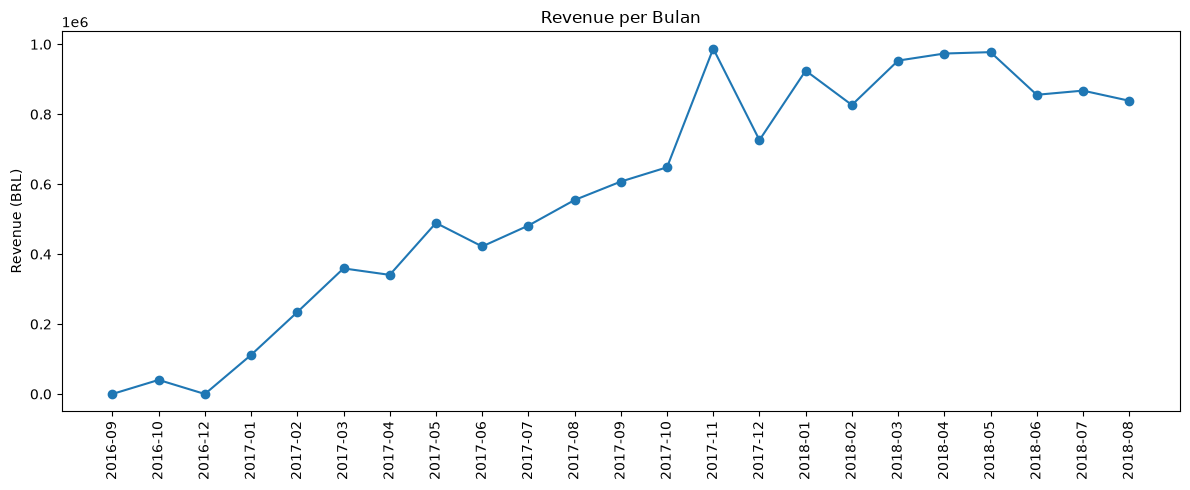

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(monthly["order_month"], monthly["revenue"], marker="o")
plt.xticks(rotation=90)
plt.title("Revenue per Bulan")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

## Kategori Produk Teratas

In [19]:
# a. Filter periode, lalu simpan sebagai df_f
df_f = df[(df["order_month"] >= "2017-01") & (df["order_month"] <= "2018-08")].copy()
print(df_f.shape)

(109872, 28)


In [20]:
# b. 10 kategori dengan revenue tertinggi
top_cat = (
    df_f.groupby("category_en")
        .agg(revenue=("price", "sum"),
             orders=("order_id", "nunique"))
        .sort_values("revenue", ascending=False)
        .head(10)
        .reset_index()
)
print(top_cat)

             category_en     revenue  orders
0          health_beauty  1229557.50    8610
1          watches_gifts  1163187.91    5489
2         bed_bath_table  1022955.77    9267
3         sports_leisure   952661.40    7512
4  computers_accessories   887944.60    6517
5        furniture_decor   706237.17    6258
6             housewares   614341.62    5734
7             cool_stuff   609158.00    3552
8                   auto   577721.09    3801
9           garden_tools   469135.40    3443


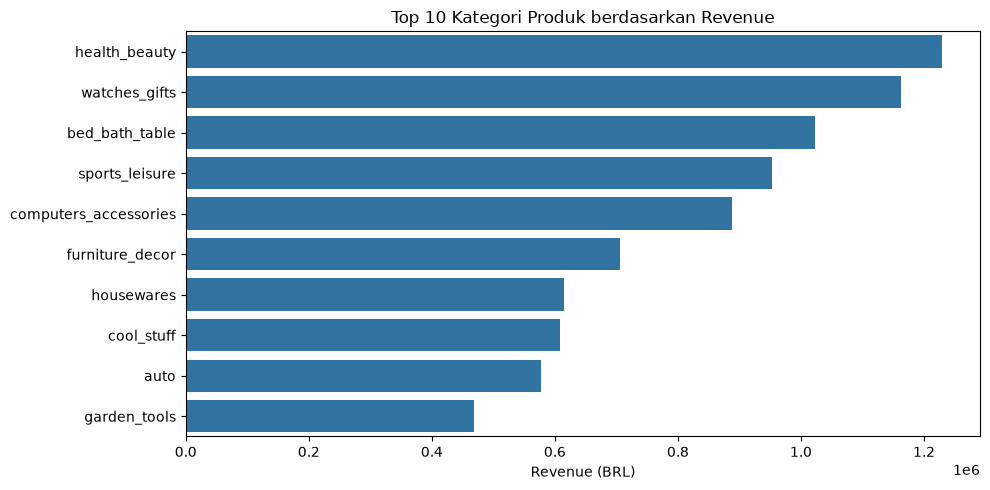

In [21]:
# c. Grafik batang
plt.figure(figsize=(10, 5))
sns.barplot(data=top_cat, x="revenue", y="category_en")
plt.title("Top 10 Kategori Produk berdasarkan Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Keterlambatan vs Review Score

In [22]:
# a. Buat tabel level order
order_level = (
    df_f.groupby("order_id")
        .agg(delivery_days=("delivery_days", "first"),
             delay_days=("delay_days", "first"),
             is_late=("is_late", "first"),
             review_score=("review_score", "first"),
             customer_state=("customer_state", "first"))
        .reset_index()
)
print(order_level.shape)
print("Persentase order terlambat:", round(order_level["is_late"].mean() * 100, 2), "%")


(96203, 6)
Persentase order terlambat: 6.79 %


In [23]:
# b. Bandingkan review order yang tepat waktu dan terlambat
late_vs_review = (
    order_level.groupby("is_late")
               .agg(avg_review=("review_score", "mean"),
                    orders=("order_id", "count"))
               .reset_index()
)
print(late_vs_review)

   is_late  avg_review  orders
0        0    4.291157   89672
1        1    2.270618    6531


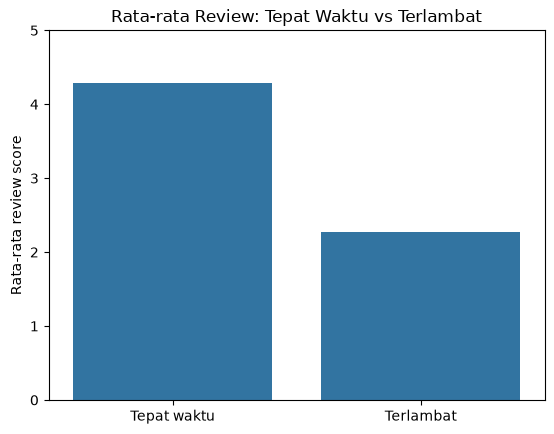

In [24]:
# c. Grafik batang
sns.barplot(data=late_vs_review, x="is_late", y="avg_review")
plt.xticks([0, 1], ["Tepat waktu", "Terlambat"])
plt.title("Rata-rata Review: Tepat Waktu vs Terlambat")
plt.xlabel("")
plt.ylabel("Rata-rata review score")
plt.ylim(0, 5)
plt.show()

## Wilayah Mana yang paling bermasalah?

In [25]:
# A. Kamus nama state dan region
state_names = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas",
    "BA": "Bahia", "CE": "Ceará", "DF": "Distrito Federal",
    "ES": "Espírito Santo", "GO": "Goiás", "MA": "Maranhão",
    "MT": "Mato Grosso", "MS": "Mato Grosso do Sul", "MG": "Minas Gerais",
    "PA": "Pará", "PB": "Paraíba", "PR": "Paraná", "PE": "Pernambuco",
    "PI": "Piauí", "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte",
    "RS": "Rio Grande do Sul", "RO": "Rondônia", "RR": "Roraima",
    "SC": "Santa Catarina", "SP": "São Paulo", "SE": "Sergipe", "TO": "Tocantins",
}

region_map = {
    "SP": "Sudeste", "RJ": "Sudeste", "MG": "Sudeste", "ES": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
    "BA": "Nordeste", "CE": "Nordeste", "PE": "Nordeste", "MA": "Nordeste",
    "PB": "Nordeste", "RN": "Nordeste", "AL": "Nordeste", "PI": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "PA": "Norte", "AM": "Norte", "RO": "Norte", "TO": "Norte",
    "AC": "Norte", "AP": "Norte", "RR": "Norte",
}

In [26]:
# B. tabel performa per state
state_perf = (
    order_level.groupby("customer_state")
               .agg(orders=("order_id", "count"),
                    late_orders=("is_late", "sum"),
                    late_pct=("is_late", "mean"),
                    avg_review=("review_score", "mean"),
                    avg_delivery=("delivery_days", "mean"))
               .reset_index()
)

state_perf["late_pct"] = state_perf["late_pct"] * 100
state_perf["state_name"] = state_perf["customer_state"].map(state_names)
state_perf["region"] = state_perf["customer_state"].map(region_map)

state_perf = state_perf[state_perf["orders"] >= 500]
state_perf = state_perf.sort_values("late_pct", ascending=False)

state_perf = state_perf[["customer_state", "state_name", "region", "orders",
                         "late_orders", "late_pct", "avg_review", "avg_delivery"]]
print(state_perf.round(2))

   customer_state          state_name        region  orders  late_orders  \
9              MA            Maranhão      Nordeste     713          125   
5              CE               Ceará      Nordeste    1273          176   
4              BA               Bahia      Nordeste    3253          396   
18             RJ      Rio de Janeiro       Sudeste   12310         1495   
13             PA                Pará         Norte     942          106   
7              ES      Espírito Santo       Sudeste    1992          214   
14             PB             Paraíba      Nordeste     516           54   
11             MS  Mato Grosso do Sul  Centro-Oeste     701           68   
15             PE          Pernambuco      Nordeste    1587          153   
23             SC      Santa Catarina           Sul    3537          291   
8              GO               Goiás  Centro-Oeste    1950          128   
22             RS   Rio Grande do Sul           Sul    5327          325   
12          

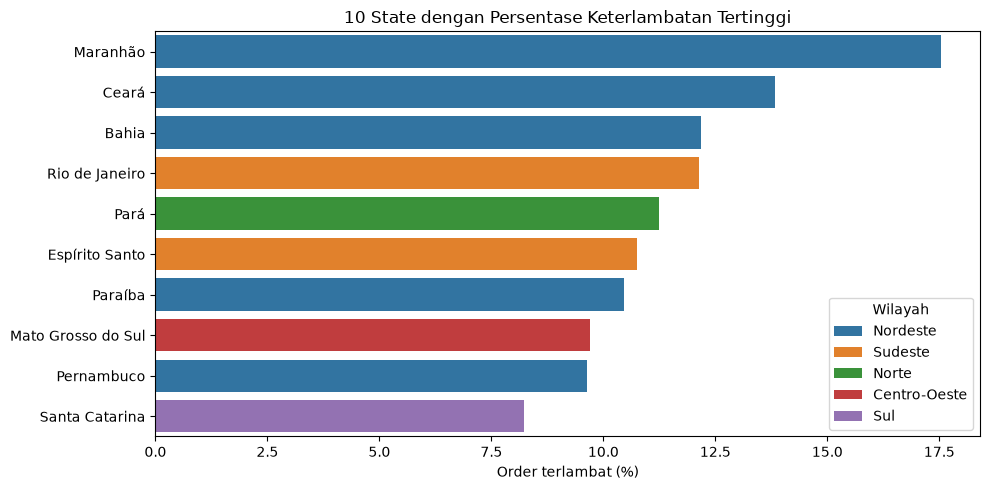

In [27]:
# C Grafik 10 state dengan persentase keterlambatan tertinggi
plt.figure(figsize=(10, 5))
sns.barplot(data=state_perf.head(10), x="late_pct", y="state_name",
            hue="region", dodge=False)
plt.title("10 State dengan Persentase Keterlambatan Tertinggi")
plt.xlabel("Order terlambat (%)")
plt.ylabel("")
plt.legend(title="Wilayah")
plt.tight_layout()
plt.show()

## Hitung RFM

In [28]:
snapshot_date = df_f["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = (
    df_f.groupby("customer_unique_id")
        .agg(last_purchase=("order_purchase_timestamp", "max"),
             frequency=("order_id", "nunique"),
             monetary=("price", "sum"))
        .reset_index()
)

rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days

print(rfm.shape)
print(rfm[["recency", "frequency", "monetary"]].describe())
print(rfm["frequency"].value_counts().head())

(93096, 5)
            recency     frequency      monetary
count  93096.000000  93096.000000  93096.000000
mean     236.711137      1.033374    141.571904
std      150.940603      0.209021    215.768405
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      218.000000      1.000000     89.700000
75%      345.000000      1.000000    154.162500
max      602.000000     15.000000  13440.000000
frequency
1    90307
2     2562
3      180
4       28
5        9
Name: count, dtype: int64


## Skore dan segmen pelanggan

In [29]:
# Skore dan segmen pelanggan

# Skor Recency: makin baru makin tinggi (4 = paling baru)
rfm["R"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)

# Skor Monetary: makin besar makin tinggi (4 = belanja terbesar)
rfm["M"] = pd.qcut(rfm["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

# Skor Frequency: 1 = sekali beli, 2 = pernah beli ulang
rfm["F"] = np.where(rfm["frequency"] >= 2, 2, 1)

# Segmen pelanggan
kondisi = [
    (rfm["F"] == 2) & (rfm["R"] >= 3),
    (rfm["F"] == 2) & (rfm["R"] <= 2),
    (rfm["F"] == 1) & (rfm["M"] == 4),
    (rfm["F"] == 1) & (rfm["R"] >= 3),
]
nama = [
    "Repeat - Aktif",
    "Repeat - Tidak Aktif",
    "Sekali Beli - Nilai Tinggi",
    "Sekali Beli - Baru",
]
rfm["segment"] = np.select(kondisi, nama, default="Sekali Beli - Tidak Aktif")

# Ringkasan per segmen
seg = (
    rfm.groupby("segment")
       .agg(customers=("customer_unique_id", "count"),
            avg_monetary=("monetary", "mean"),
            total_monetary=("monetary", "sum"))
       .reset_index()
)
seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["pct_revenue"] = seg["total_monetary"] / seg["total_monetary"].sum() * 100
print(seg.sort_values("customers", ascending=False).round(2))

                      segment  customers  avg_monetary  total_monetary  \
4   Sekali Beli - Tidak Aktif      34381         69.50      2389315.80   
2          Sekali Beli - Baru      34327         71.14      2442103.09   
3  Sekali Beli - Nilai Tinggi      21599        352.93      7623004.02   
0              Repeat - Aktif       1534        264.46       405677.44   
1        Repeat - Tidak Aktif       1255        254.72       319677.60   

   pct_customers  pct_revenue  
4          36.93        18.13  
2          36.87        18.53  
3          23.20        57.84  
0           1.65         3.08  
1           1.35         2.43  


## Cohort Retention

months_since      0     1     2     3     4     5     6
cohort_month                                           
2017-01       100.0  0.28  0.28  0.14  0.42  0.14  0.42
2017-02       100.0  0.18  0.31  0.12  0.43  0.12  0.25
2017-03       100.0  0.44  0.36  0.40  0.36  0.16  0.16
2017-04       100.0  0.62  0.22  0.18  0.27  0.27  0.35
2017-05       100.0  0.46  0.46  0.29  0.29  0.32  0.41
2017-06       100.0  0.49  0.40  0.43  0.30  0.40  0.36
2017-07       100.0  0.53  0.35  0.24  0.29  0.21  0.32
2017-08       100.0  0.69  0.35  0.27  0.35  0.52  0.30
2017-09       100.0  0.70  0.55  0.27  0.45  0.22  0.22
2017-10       100.0  0.72  0.25  0.09  0.23  0.21  0.21
2017-11       100.0  0.57  0.37  0.17  0.17  0.18  0.11
2017-12       100.0  0.21  0.28  0.34  0.26  0.21  0.17
2018-01       100.0  0.34  0.37  0.29  0.29  0.16  0.18
2018-02       100.0  0.35  0.40  0.30  0.25  0.22  0.21
2018-03       100.0  0.40  0.30  0.30  0.12  0.12   NaN
2018-04       100.0  0.59  0.30  0.24  0.14   Na

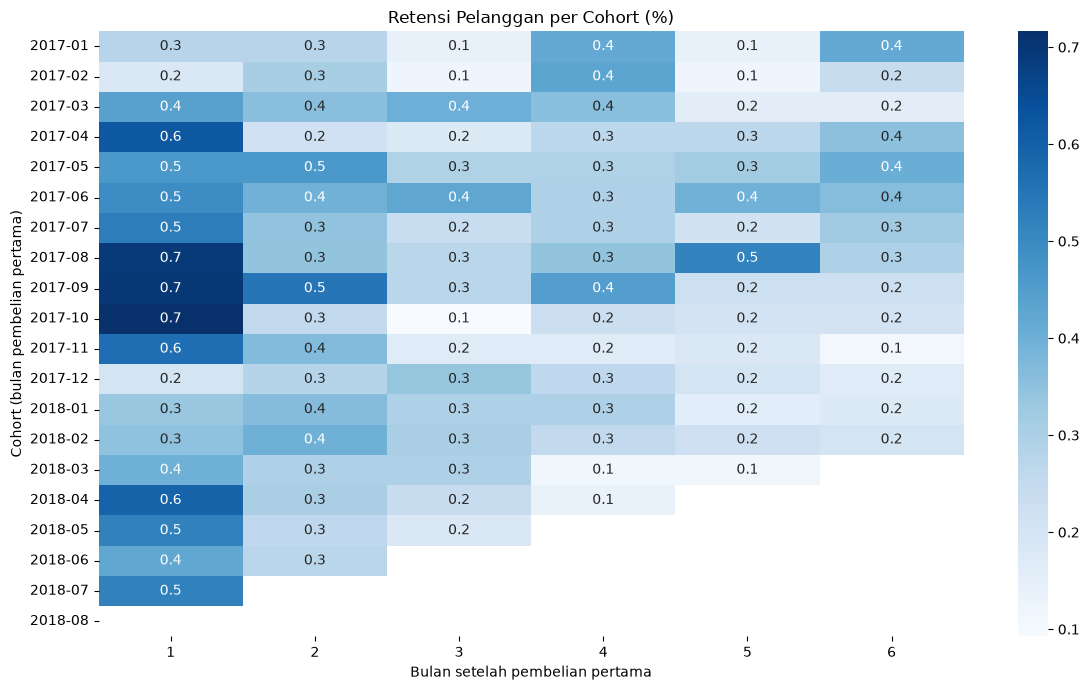

In [30]:
# 1. Satu baris per order, lalu ambil bulan pembelian
cohort_df = (
    df_f[["customer_unique_id", "order_id", "order_purchase_timestamp"]]
    .drop_duplicates("order_id")
    .copy()
)
cohort_df["order_month"] = cohort_df["order_purchase_timestamp"].dt.to_period("M")

# 2. Bulan pembelian pertama tiap pelanggan = cohort
cohort_df["cohort_month"] = (
    cohort_df.groupby("customer_unique_id")["order_month"].transform("min")
)

# 3. Selisih bulan antara order dan bulan cohort
cohort_df["months_since"] = (
    (cohort_df["order_month"].dt.year - cohort_df["cohort_month"].dt.year) * 12
    + (cohort_df["order_month"].dt.month - cohort_df["cohort_month"].dt.month)
)

# 4. Hitung pelanggan unik per cohort per bulan ke-n
cohort_counts = (
    cohort_df.groupby(["cohort_month", "months_since"])["customer_unique_id"]
             .nunique()
             .reset_index()
)

# 5. Ubah ke bentuk tabel, lalu jadikan persen
cohort_pivot = cohort_counts.pivot(
    index="cohort_month", columns="months_since", values="customer_unique_id"
)
retention = cohort_pivot.divide(cohort_pivot[0], axis=0) * 100

print(retention.iloc[:, :7].round(2))

# 6. Heatmap (bulan ke-1 sampai ke-6)
plt.figure(figsize=(12, 7))
sns.heatmap(retention.iloc[:, 1:7], annot=True, fmt=".1f", cmap="Blues")
plt.title("Retensi Pelanggan per Cohort (%)")
plt.xlabel("Bulan setelah pembelian pertama")
plt.ylabel("Cohort (bulan pembelian pertama)")
plt.tight_layout()
plt.show()

# Ekspor CSV bersih

In [31]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import os
os.makedirs("data/tableau", exist_ok=True)

# 1. Pastikan kolom nama state dan wilayah ada di kedua tabel
for d in (df_f, order_level):
    d["state_name"] = d["customer_state"].map(state_names)
    d["region"] = d["customer_state"].map(region_map)

# 2. Siapkan tiap dataset
cols_items = ["order_id", "customer_unique_id", "order_month", "price", "freight_value",
              "category_en", "review_score", "customer_state", "state_name", "region",
              "seller_id", "delivery_days", "delay_days", "is_late"]

monthly_f = monthly[monthly["order_month"] >= "2017-01"]

retention_long = (
    retention.reset_index()
             .melt(id_vars="cohort_month", var_name="months_since", value_name="retention_pct")
             .dropna()
)
retention_long["cohort_month"] = retention_long["cohort_month"].astype(str)

# 3. Kumpulkan dalam satu dictionary
exports = {
    "orders_items":      df_f[cols_items],
    "orders_level":      order_level,
    "monthly_trend":     monthly_f,
    "state_performance": state_perf,
    "customer_rfm":      rfm,
    "cohort_retention":  retention_long,
}

# 4. Simpan semuanya ke Excel
for name, d in exports.items():
    d.to_excel(f"data/tableau/{name}.xlsx", index=False)
    print(f"{name:20s} {d.shape[0]:>7,} baris, {d.shape[1]:>2} kolom")

orders_items         109,872 baris, 14 kolom
orders_level          96,203 baris,  8 kolom
monthly_trend             20 baris,  3 kolom
state_performance         17 baris,  8 kolom
customer_rfm          93,096 baris,  9 kolom
cohort_retention         207 baris,  3 kolom
